# Erste Untersuchung der NPPAD-Daten

Dieses Notebook gehört zum Forschungsprojekt über Explainable AI
für die Anomalieerkennung in simulierten Kernreaktordaten.

Zunächst werden drei kleine Originaldateien aus NPPAD untersucht:
Normalbetrieb, LOCA und SGATR.

Wir prüfen die Datenstruktur, fehlende und ungültige Werte,
konstante Prozessgrößen sowie die Zeitstempel.
Anschließend betrachten wir zwei Prozessgrößen grafisch.

In diesem Schritt wird noch kein Modell trainiert.

Datenquelle:
Qi et al. (2022), An open time-series simulated dataset covering
various accidents for nuclear power plants.
https://doi.org/10.1038/s41597-022-01879-1

In [6]:
from pathlib import Path
from urllib.request import Request, urlopen
import hashlib

import pandas as pd
import matplotlib.pyplot as plt

print("Arbeitsordner:", Path.cwd())
print("Pandas-Version:", pd.__version__)

Arbeitsordner: c:\Users\33alb\OneDrive\Documents\Proiect_Cercetare
Pandas-Version: 2.3.3


In [7]:
Path("data").mkdir(exist_ok=True)

version = "a8d54ed0ed2c037bd39938d51f46c8f0df94b002"

base_url = (
    "https://raw.githubusercontent.com/"
    "thu-inet/NuclearPowerPlantAccidentData/"
    f"{version}/Operation_csv_data"
)

expected_hashes = {
    "Normal": "53673a2717f7ca84441f55b11bf37e96b8be425e793b7495472f4b7022ff3e9a",
    "LOCA": "0375ea99d6968bc5dae7f20127203c60ddefd1480d6b8f6700b199632987c4b3",
    "SGATR": "cbd1dafaee2a3b8da3fe9902d3c340d48a3ebed04b1b26d0e63c3b965e979436"
}

datasets = {}
sources = []

for name, expected_hash in expected_hashes.items():
    url = f"{base_url}/{name}/1.csv"
    file = Path("data") / f"{name}.csv"

    if not file.exists():
        request = Request(
            url,
            headers={"User-Agent": "Research-L4"}
        )

        with urlopen(request, timeout=60) as response:
            file.write_bytes(response.read())

    actual_hash = hashlib.sha256(file.read_bytes()).hexdigest()

    if actual_hash != expected_hash:
        raise ValueError(
            f"Datei stimmt nicht mit der Quelle ueberein: {file}"
        )

    datasets[name] = pd.read_csv(file)

    sources.append({
        "scenario": name,
        "url": url,
        "sha256": actual_hash
    })

    print(name, datasets[name].shape)

pd.DataFrame(sources).to_csv("data_sources.csv", index=False)

Normal (302, 97)
LOCA (475, 97)
SGATR (551, 97)


In [8]:
rows = []

reference_columns = list(datasets["Normal"].columns)

for name, frame in datasets.items():
    if list(frame.columns) != reference_columns:
        raise ValueError(f"Unterschiedliche Spalten bei {name}")

    if "TIME" not in frame.columns or len(frame) < 2:
        raise ValueError(
            f"Zeitspalte oder Messzeilen fehlen bei {name}"
        )

    numeric = frame.apply(pd.to_numeric, errors="coerce")

    invalid = numeric.isna() & frame.notna()
    infinite = numeric.isin([float("inf"), float("-inf")])

    time = numeric["TIME"]
    steps = time.diff().dropna()

    regular = (
        time.notna().all()
        and not infinite["TIME"].any()
        and (steps > 0).all()
        and steps.nunique() == 1
    )

    measurements = numeric.drop(columns="TIME")
    constant = (measurements.nunique() == 1).sum()

    rows.append({
        "Datensatz": name,
        "Zeilen": len(frame),
        "Spalten": frame.shape[1],
        "Fehlend": int(frame.isna().sum().sum()),
        "Keine_Zahl": int(invalid.sum().sum()),
        "Unendlich": int(infinite.sum().sum()),
        "Konstante_Groessen": int(constant),
        "Regelmaessige_Zeit": bool(regular),
        "Zeitschritt": float(steps.iloc[0]) if regular else None
    })

summary = pd.DataFrame(rows)

summary.to_csv("data_check.csv", index=False)

summary

,Datensatz,Zeilen,Spalten,Fehlend,Keine_Zahl,Unendlich,Konstante_Groessen,Regelmaessige_Zeit,Zeitschritt
0,Normal,302,97,0,0,0,40,True,10.0
1,LOCA,475,97,0,0,0,25,True,10.0
2,SGATR,551,97,0,0,0,49,True,10.0


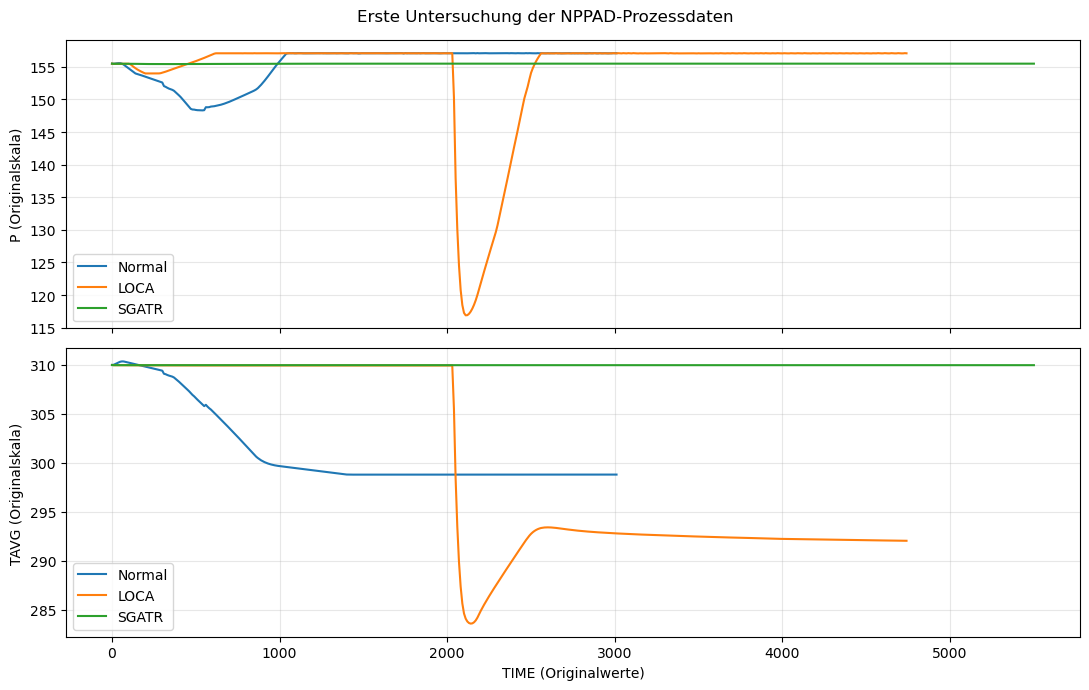

In [9]:
Path("figures").mkdir(exist_ok=True)

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

for name, frame in datasets.items():
    axes[0].plot(
        frame["TIME"],
        frame["P"],
        label=name
    )

    axes[1].plot(
        frame["TIME"],
        frame["TAVG"],
        label=name
    )

axes[0].set_ylabel("P (Originalskala)")
axes[1].set_ylabel("TAVG (Originalskala)")
axes[1].set_xlabel("TIME (Originalwerte)")

for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)

fig.suptitle("Erste Untersuchung der NPPAD-Prozessdaten")
fig.tight_layout()

fig.savefig("figures/01_signalverlaeufe.png", dpi=150)

plt.show()

## Erste Ergebnisse und nächste Schritte

Die drei untersuchten Dateien enthalten dieselben 97 Spalten.
Dazu gehören die Zeitspalte TIME und 96 weitere Prozessgrößen.

In den ausgewählten Dateien wurden keine fehlenden,
nichtnumerischen oder unendlichen Werte gefunden.
Die Zeitstempel steigen regelmäßig in Schritten von 10 an.

Mehrere Prozessgrößen bleiben innerhalb einzelner Dateien konstant.
Eine spätere Auswahl von Eingangsgrößen muss anhand der
Trainingsdaten erfolgen.

Die Diagramme zeigen unterschiedliche zeitliche Verläufe.
Sie erlauben noch keine Aussage darüber, welche Größen ein
trainiertes Modell verwenden wird oder welche Unfallursache vorliegt.

Dieser kleine Datenausschnitt dient zunächst der Datenuntersuchung.
Vor dem Training müssen unabhängige Simulationsläufe,
Betriebsbedingungen und Ereigniszeitpunkte geprüft werden.
Anschließend können die Daten aufgeteilt und Zeitfenster gebildet werden.